# Lab 2: K-Nearest Neighbors and Radius Neighbors on the Wine Dataset

Name: Sandip Sitaula
Course: MSCS 634 - Advanced Big Data and Data Mining
Lab: Lab 2 - KNN and Radius Neighbors Classifiers

## Step 1: Load and prepare the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.preprocessing import StandardScaler

wine = load_wine()
X, y = wine.data, wine.target
df = pd.DataFrame(X, columns=wine.feature_names)
df['target'] = y
print('Shape:', df.shape)
print('Classes:', [str(n) for n in wine.target_names])
df.head()

Shape: (178, 14)
Classes: ['class_0', 'class_1', 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [2]:
df.describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
alcohol,13.000618,0.811827,11.03,14.83
malic_acid,2.336348,1.117146,0.74,5.80
ash,2.366517,0.274344,1.36,3.23
alcalinity_of_ash,19.494944,3.339564,10.60,30.00
magnesium,99.741573,14.282484,70.00,162.00
total_phenols,2.295112,0.625851,0.98,3.88
flavanoids,2.029270,0.998859,0.34,5.08
nonflavanoid_phenols,0.361854,0.124453,0.13,0.66
proanthocyanins,1.590899,0.572359,0.41,3.58
color_intensity,5.058090,2.318286,1.28,13.00


Missing values: 0
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


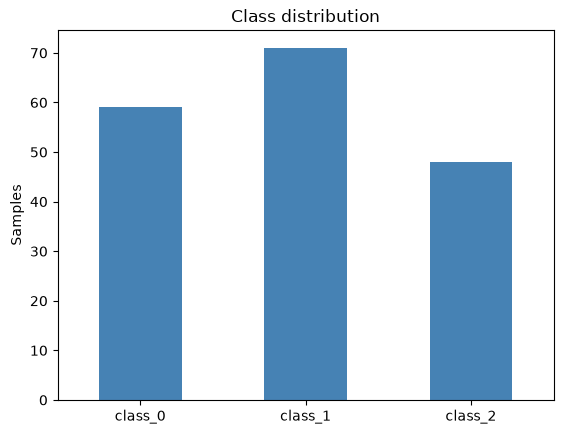

In [3]:
print('Missing values:', df.isna().sum().sum())
counts = pd.Series(y).map(dict(enumerate(wine.target_names))).value_counts().sort_index()
print(counts)
counts.plot(kind='bar', color='steelblue', title='Class distribution')
plt.ylabel('Samples')
plt.xticks(rotation=0)
plt.show()

The dataset has 178 samples, 13 numeric features, no missing values, and three moderately imbalanced classes (59 / 71 / 48). Feature scales differ a lot: `proline` ranges from roughly 278 to 1680, while most other features are below 20. This matters for distance-based models, since `proline` will dominate the distance. The lab asks for radius values of 350-600, which only make sense on the raw (unscaled) features, so I keep them unscaled for the main experiments.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (142, 13) Test: (36, 13)


I used `stratify=y` so both splits keep the same class proportions, and `random_state=42` so the results are reproducible.

## Step 2: K-Nearest Neighbors

In [5]:
k_values = [1, 5, 11, 15, 21]
knn_acc = {}
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    knn_acc[k] = knn.score(X_test, y_test)

knn_df = pd.DataFrame({'k': k_values, 'accuracy': knn_acc.values()})
knn_df

,k,accuracy
0,1,0.777778
1,5,0.805556
2,11,0.805556
3,15,0.805556
4,21,0.805556


## Step 3: Radius Neighbors

A test point with no training points inside the radius has no neighbors to vote, and sklearn raises an error by default. I set `outlier_label='most_frequent'` so those points get the most common class, and I count how many points hit that case to see if it affects the results.

In [6]:
radii = [350, 400, 450, 500, 550, 600]
rnn_acc, rnn_empty = {}, {}
for r in radii:
    rnn = RadiusNeighborsClassifier(radius=r, outlier_label='most_frequent')
    rnn.fit(X_train, y_train)
    rnn_acc[r] = rnn.score(X_test, y_test)
    neighbors = rnn.radius_neighbors(X_test, return_distance=False)
    rnn_empty[r] = sum(len(n) == 0 for n in neighbors)

rnn_df = pd.DataFrame({'radius': radii, 'accuracy': rnn_acc.values(),
                       'test points with no neighbors': rnn_empty.values()})
rnn_df

,radius,accuracy,test points with no neighbors
0,350,0.722222,0
1,400,0.694444,0
2,450,0.694444,0
3,500,0.694444,0
4,550,0.666667,0
5,600,0.666667,0


## Step 4: Visualize and compare

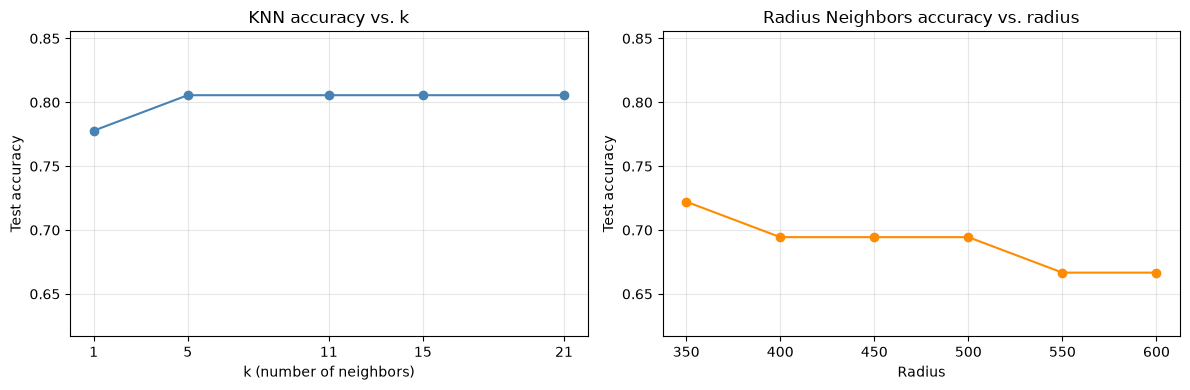

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(k_values, list(knn_acc.values()), marker='o', color='steelblue')
ax[0].set_title('KNN accuracy vs. k')
ax[0].set_xlabel('k (number of neighbors)')
ax[0].set_ylabel('Test accuracy')
ax[0].set_xticks(k_values)

ax[1].plot(radii, list(rnn_acc.values()), marker='o', color='darkorange')
ax[1].set_title('Radius Neighbors accuracy vs. radius')
ax[1].set_xlabel('Radius')
ax[1].set_ylabel('Test accuracy')
ax[1].set_xticks(radii)

lo = min(*knn_acc.values(), *rnn_acc.values()) - 0.05
hi = max(*knn_acc.values(), *rnn_acc.values()) + 0.05
for a in ax:
    a.set_ylim(lo, hi)
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
best_k = max(knn_acc, key=knn_acc.get)
best_r = max(rnn_acc, key=rnn_acc.get)
print(f'Best KNN: k={best_k}, accuracy={knn_acc[best_k]:.3f}')
print(f'Best RNN: radius={best_r}, accuracy={rnn_acc[best_r]:.3f}')

Best KNN: k=5, accuracy=0.806
Best RNN: radius=350, accuracy=0.722


The test set has only 36 samples, so one sample is about 2.8 percentage points of accuracy. Differences of one or two samples should not be over-interpreted.

### Extra check: effect of feature scaling (KNN only)

In [9]:
scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)
for k in k_values:
    acc = KNeighborsClassifier(n_neighbors=k).fit(Xs_train, y_train).score(Xs_test, y_test)
    print(f'k={k:2d}  scaled accuracy={acc:.3f}  (unscaled={knn_acc[k]:.3f})')

k= 1  scaled accuracy=0.972  (unscaled=0.778)
k= 5  scaled accuracy=0.972  (unscaled=0.806)
k=11  scaled accuracy=1.000  (unscaled=0.806)
k=15  scaled accuracy=1.000  (unscaled=0.806)
k=21  scaled accuracy=1.000  (unscaled=0.806)


### Observations

KNN: Accuracy went from 0.778 at k=1 to 0.806 at k=5, then stayed the same up to k=21. With k=1 the answer depends on just one neighbor, which can be a noisy point. A few more neighbors fix that. After that, more neighbors did not help. The main problem is that proline is much bigger than the other features, so it controls the distance.

RNN: Accuracy went down as the radius went up: 0.722 at 350, 0.694 from 400 to 500, and 0.667 at 550 and 600. A bigger radius includes more training points from other classes, so the vote gets mixed. No test point had zero neighbors, so the outlier setting made no difference.

Comparison: KNN was better than RNN at every setting (best 0.806 vs 0.722). KNN was also steadier. The radius values 350 to 600 are big for this data, so each point has many neighbors. Also, the lab gave fixed radius values and I did not tune k further, so this is not a perfectly fair comparison.

Scaling: Scaling the features helped much more than changing k or radius. KNN reached 0.972 to 1.000. So the lower scores above mostly come from proline dominating. The test set has only 36 wines, so I would not trust exact numbers, but the gap is several wines, not just one.

When to use which:
- KNN is a good default. It always has k neighbors to vote, and k is easy to understand and tune.
- RNN is better when a fixed distance has a real meaning and the data is spread evenly. In sparse areas it may find no neighbors, and in crowded areas it may find too many.
- The radius depends on the size of the features, so it must be chosen again after scaling.